# Exploratory Data Analysis

We first load the data using the `s1stack.load_stacks` function. This returns, for each orbit, a 'stack' of gridded data as a single array. For Orbit 103 there are 61 dates, so we will get a 61x918x811 array. 

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

import plot_helpers
from s1stack import load_stacks

OUT = Path("eda_figures")
OUT.mkdir(exist_ok=True)
ORBITS = {1: "orbit 1 (asc, 44.8°)", 52: "orbit 52 (desc, 37.7°)", 103: "orbit 103 (asc, 36.5°)"}

# one (n_dates, height, width) stack per orbit, -9999 masked to NaN
idxs, stacks = load_stacks(ORBITS)
for o in ORBITS:
    print(f"orbit {o}: {stacks[o].shape[0]} dates, grid {stacks[o].shape[1]} x {stacks[o].shape[2]}")

orbit 1: 58 dates, grid 918 x 811
orbit 52: 61 dates, grid 918 x 811
orbit 103: 60 dates, grid 918 x 811


We plot the mean and standard deviation of the backscatter coefficient over the whole time period for each of the three orbits for comparison. 

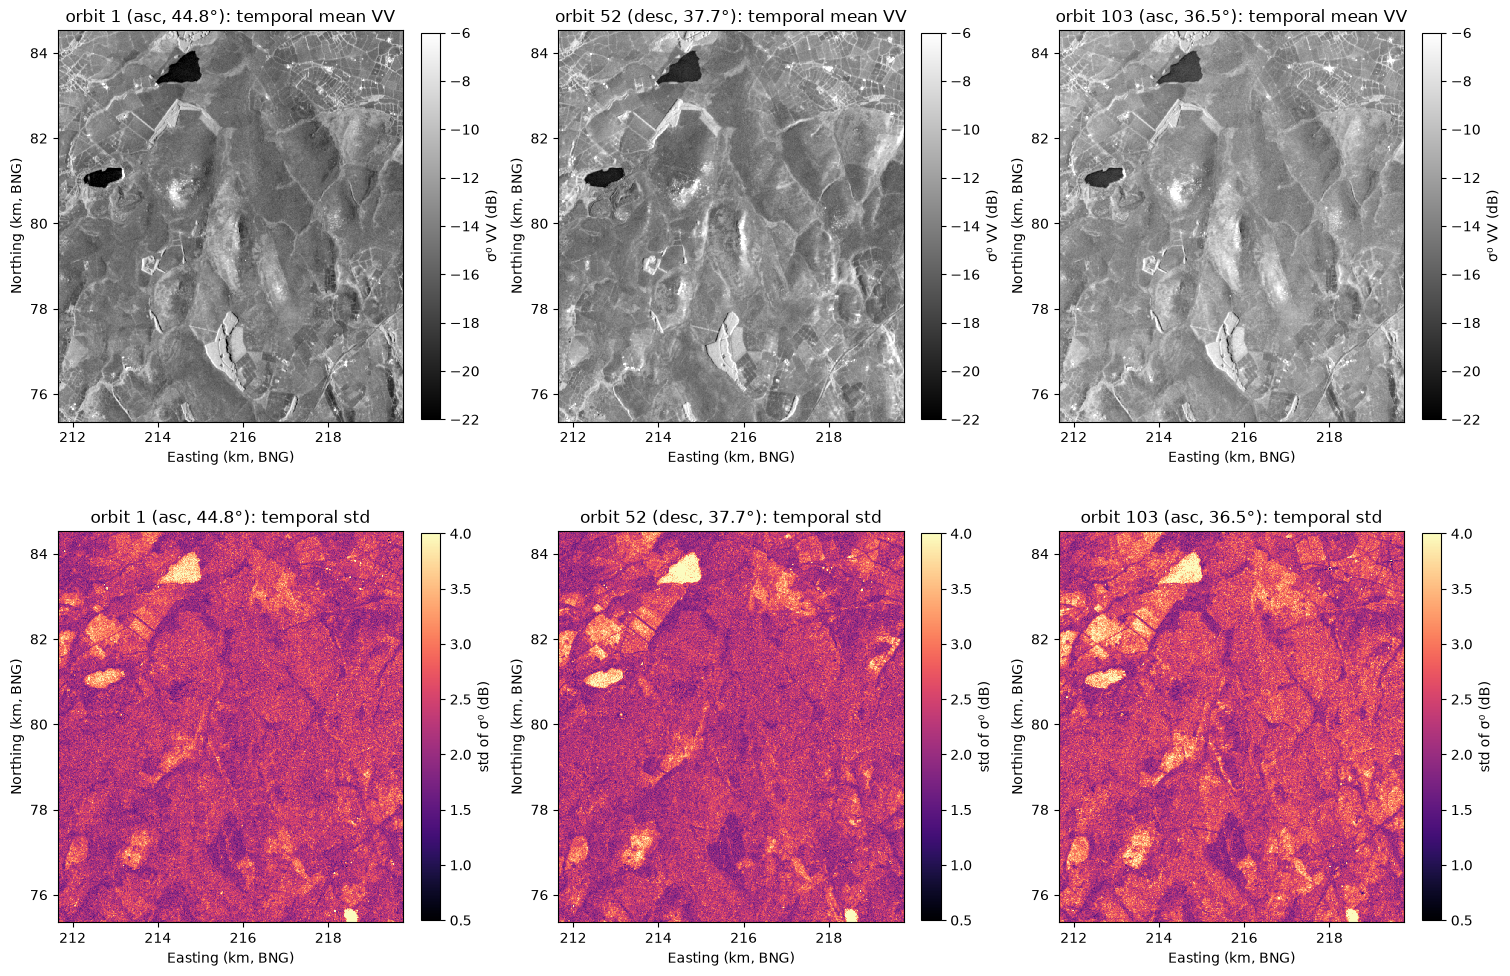

In [2]:
fig, axs = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
for j, o in enumerate(ORBITS):
    mean = np.nanmean(stacks[o], 0)
    std = np.nanstd(stacks[o], 0)
    im = plot_helpers.imshow_km(axs[0, j], mean, cmap="gray", vmin=-22, vmax=-6)
    axs[0, j].set_title(f"{ORBITS[o]}: temporal mean VV")
    fig.colorbar(im, ax=axs[0, j], label="σ⁰ VV (dB)", shrink=0.8)
    im = plot_helpers.imshow_km(axs[1, j], std, cmap="magma", vmin=0.5, vmax=4)
    axs[1, j].set_title(f"{ORBITS[o]}: temporal std")
    fig.colorbar(im, ax=axs[1, j], label="std of σ⁰ (dB)", shrink=0.8)
fig.savefig(OUT / "01_mean_std_maps.png", dpi=130)
plt.show()

We see some particularly dark areas (in the mean, top row) corresponding to bodies of water, and lighter areas (probably fields). For any further analysis we should mask these areas and focus of the peat. In addition the the Sentinel-1 data we also download England Peat Map layers (Natural England open data) and land-cover and elevation (from Earth Engine) using `download_peat_map.py` and `download_ancillary.py`. 

The script `make_mask.py` writes `peat_mask.tif` to our data directory. 

We now plot the mask for a visual check. The plot also shows restoration areas from Natural England's *Peatland Restoration Register*.

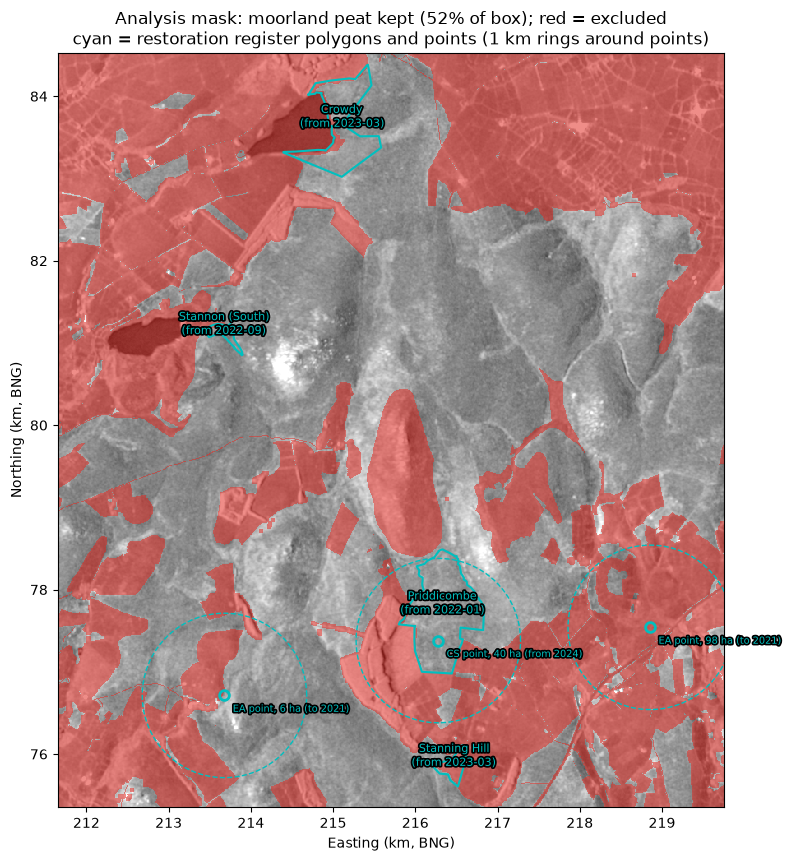

In [3]:
with rasterio.open("data/ancillary/peat_mask.tif") as src:
    keep = src.read(1).astype(bool)
restoration_areas = plot_helpers.get_restoration_areas(polygons_only=False)

# Point records give only a grid reference, so the restored area's extent is unknown.
# The largest location sums to ~98 ha (EA, 45 + 53 ha), a circle of radius ~0.56 km;
# draw a 1 km ring around each point as a margin to avoid when choosing a comparison patch.
POINT_BUFFER_KM = 1.0

fig, ax = plt.subplots(figsize=(8, 8.5), constrained_layout=True)
plot_helpers.imshow_km(ax, np.nanmean(stacks[103], 0), cmap="gray", vmin=-22, vmax=-6)
plot_helpers.imshow_km(ax, np.where(keep, np.nan, 1), cmap="Reds", vmin=0, vmax=1.5, alpha=0.55)
plot_helpers.plot_restoration_areas(ax, restoration_areas, point_buffer_km=POINT_BUFFER_KM)
ax.set_xlim(plot_helpers.KM[:2])
ax.set_ylim(plot_helpers.KM[2:])

ax.set_title(f"Analysis mask: moorland peat kept ({keep.mean():.0%} of box); red = excluded\n"
             f"cyan = restoration register polygons and points ({POINT_BUFFER_KM:g} km rings around points)")
fig.savefig(OUT / "02_mask.png", dpi=110)
plt.show()

The four polygons on the map showing restoration areas correspond to four ***Nature for Climate Peatland Grant Scheme 2021–25*** projects led by *South West Water*. Five other locations for restoration are given only as points, plotted with a 1km radius border. 

## MASKED AREA TIME SERIES (Mean backscatter over time)

For each orbit we take the median VV over all masked peat pixels on each acquisition date $t_i$. This gives one value per date, $R(t_i)$: the moor-wide signal. 

We fit a curve $\hat R(t)$ to the data, leaving the residuals $\varepsilon_i$ as is:

$$R(t_i) = \hat R(t_i) + \varepsilon_i,$$

where

$$\hat R(t_i) = \underbrace{\beta_0 + \beta_1 (t_i - 2024)}_{\text{level + trend}} + \underbrace{\gamma_1 \sin(2\pi t_i) + \gamma_2 \cos(2\pi t_i)}_{\text{annual cycle}}$$

with $t_i$ in decimal years. The coefficients $\beta_0, \beta_1, \gamma_1, \gamma_2$ are estimated by ordinary least squares (`trend.fit_series`).

$\beta_1$ is the moor-wide trend in dB/yr. Its standard error is widened because a wet or dry spell carries over between consecutive 12-day acquisitions, so they are not independent evidence about the trend.

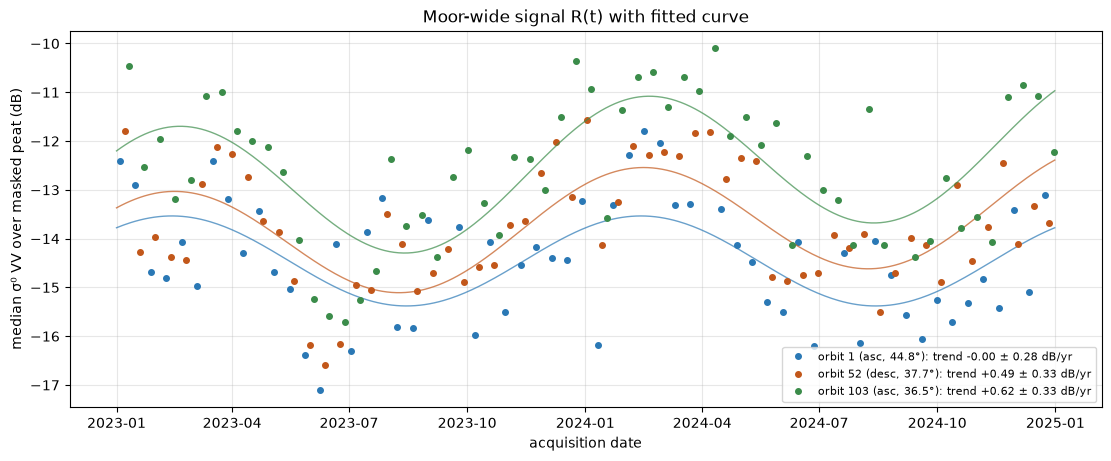

,mean level (dB),trend (dB/yr),trend SE,annual amplitude (dB),seasonal peak (day of year),residual std (dB)
orbit,,,,,,
1,-14.46,-0.00,0.28,0.92,43.08,1.07
52,-13.76,0.49,0.33,1.16,41.22,0.91
103,-12.61,0.62,0.33,1.45,45.63,1.05


,1,52,103
monthly R(t) correlation,,,
1,1.00,0.72,0.71
52,0.72,1.00,0.87
103,0.71,0.87,1.00


In [4]:
from s1stack import block_mean, decimal_year
from trend import design, fit_cells, fit_series

ORBIT_COLORS = {1: "#2a78b5", 52: "#c2571a", 103: "#3b8c4a"}

# moor-wide signal R(t): median VV over all masked peat pixels on each date
moor = {o: np.nanmedian(stacks[o][:, keep], axis=1) for o in ORBITS}
tyears = {o: decimal_year(idxs[o].time) for o in ORBITS}
moor_fits = {o: fit_series(tyears[o], moor[o]) for o in ORBITS}

tt = np.linspace(2023, 2025, 400)
tt_dates = pd.Timestamp("2023-01-01") + pd.to_timedelta((tt - 2023) * 365.25, "D")
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
for o in ORBITS:
    f = moor_fits[o]
    ax.plot(idxs[o].time, moor[o], "o", ms=4, color=ORBIT_COLORS[o],
            label=f"{ORBITS[o]}: trend {f.slope:+.2f} ± {f.se:.2f} dB/yr")
    ax.plot(tt_dates, design(tt) @ f.beta, "-", lw=1, alpha=0.7, color=ORBIT_COLORS[o])
ax.set_xlabel("acquisition date")
ax.set_ylabel("median σ⁰ VV over masked peat (dB)")
ax.set_title("Moor-wide signal R(t) with fitted curve")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.savefig(OUT / "03_moor_wide_series.png", dpi=130)
plt.show()

# peak day of year of the fitted annual cycle: maximise g1 sin(wt) + g2 cos(wt)
summary = pd.DataFrame({
    o: {"mean level (dB)": f.beta[0], "trend (dB/yr)": f.slope, "trend SE": f.se,
        "annual amplitude (dB)": f.amplitude,
        "seasonal peak (day of year)": np.degrees(np.arctan2(f.beta[2], f.beta[3])) % 360 / 360 * 365.25,
        "residual std (dB)": f.resid_std}
    for o, f in moor_fits.items()}).T.round(2)
summary.index.name = "orbit"
display(summary)

# do the orbits see the same weather? correlate monthly means of R(t) between orbits
monthly = pd.DataFrame({o: pd.Series(moor[o], index=idxs[o].time).resample("MS").mean() for o in ORBITS})
display(monthly.corr().round(2).rename_axis("monthly R(t) correlation"))

## SUBTRACTING THE ANNUAL CYCLE

To see how the moor-wide signal changes over the two years, we subtract only the fitted annual cycle ($\gamma_1 \sin 2\pi t + \gamma_2 \cos 2\pi t$) and each orbit's mean level $\beta_0$ from $R(t)$. What's left is the trend plus weather anomalies. A 90-day running mean makes the slower changes visible, and the dashed lines are the fitted trends.

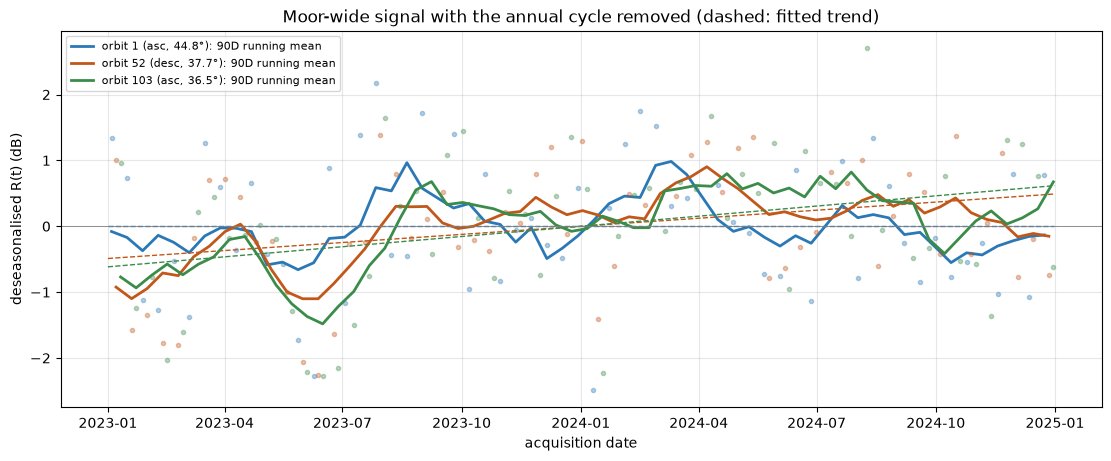

In [5]:
# Deseasonalised moor-wide signal: R(t) minus the fitted annual cycle and mean level.
# The annual cycle removed here comes from moor_fits (previous section), which fitted trend and
# annual cycle together.

SMOOTH = "90D"
deseason = {}
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
for o in ORBITS:
    f = moor_fits[o]
    seasonal = design(tyears[o])[:, [0, 2, 3]] @ f.beta[[0, 2, 3]]  # b0 + g1 sin + g2 cos
    deseason[o] = pd.Series(moor[o] - seasonal, index=idxs[o].time)
    c = ORBIT_COLORS[o]
    ax.plot(deseason[o].index, deseason[o], "o", ms=3, alpha=0.35, color=c)
    ax.plot(deseason[o].rolling(SMOOTH, center=True).mean(), "-", lw=2, color=c,
            label=f"{ORBITS[o]}: {SMOOTH} running mean")
    ax.plot(tt_dates, design(tt)[:, 1] * f.slope, "--", lw=1, color=c)
ax.axhline(0, color="0.5", lw=0.6)
ax.set_xlabel("acquisition date")
ax.set_ylabel("deseasonalised R(t) (dB)")
ax.set_title("Moor-wide signal with the annual cycle removed (dashed: fitted trend)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.savefig(OUT / "04_moor_wide_deseasonalised.png", dpi=130)
plt.show()

## SUBTRACTING THE MOOR-WIDE SIGNAL

The moor-wide signal mixes weather, seasonal vegetation change and any orbit-specific sensitivity, so a trend in it can't be tied to a place on the moor. To see *where* the moor changes, we:

1. average the masked pixels into 100 m cells (cells need at least 50% masked pixels), to reduce speckle;
2. subtract the moor-wide signal $R(t)$ from every cell on each date, leaving the local anomaly $a(t) = \text{cell}(t) - R(t)$;
3. fit the same trend + annual cycle model to $a(t)$ in every cell (`trend.fit_cells`). The slope is the **local trend**: brightening or darkening relative to the moor as a whole.

The maps show, for each orbit, the **raw** slope (fitted to $\text{cell}(t)$ without subtracting $R(t)$) and the **local** slope.

/Users/joshua/Academic/Other/OSC_peatland/code/s1stack.py:84: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis=(-3, -1))


3801 of 7371 100 m cells used


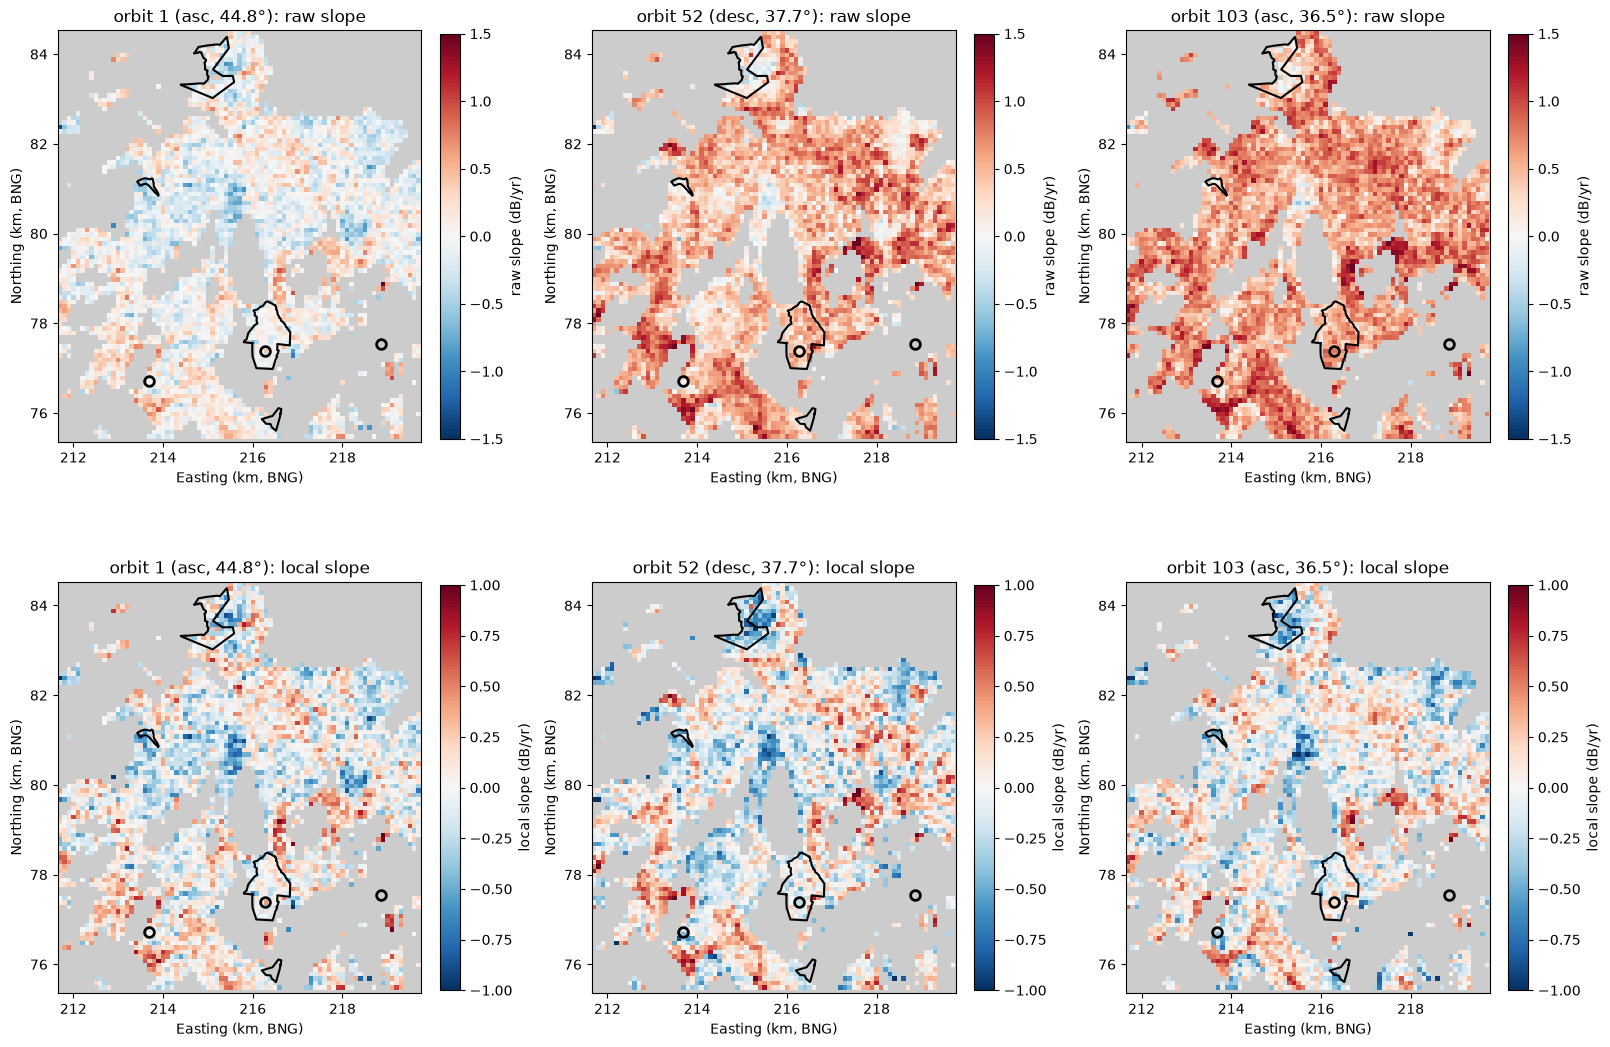

In [6]:
K = 10           # 10 x 10 pixels -> 100 m cells
MIN_COVER = 0.5  # fraction of a cell's pixels that must be in the mask
cell_ok = block_mean(keep[None].astype(float), K)[0] >= MIN_COVER
EXT_100M = plot_helpers.block_extent_km(K)

raw_fits, local_fits = {}, {}
for o in ORBITS:
    cells = block_mean(np.where(keep, stacks[o], np.nan), K)  # (n_dates, rows, cols) at 100 m
    cells[:, ~cell_ok] = np.nan
    raw_fits[o] = fit_cells(tyears[o], cells)
    local_fits[o] = fit_cells(tyears[o], cells - moor[o][:, None, None])
print(f"{cell_ok.sum()} of {cell_ok.size} 100 m cells used")

fig, axs = plt.subplots(2, 3, figsize=(16, 11), constrained_layout=True)
for j, o in enumerate(ORBITS):
    for i, (fits, kind, lim) in enumerate([(raw_fits, "raw", 1.5), (local_fits, "local", 1.0)]):
        ax = axs[i, j]
        ax.set_facecolor("0.8")
        im = plot_helpers.imshow_km(ax, fits[o].slope, EXT_100M, cmap="RdBu_r", vmin=-lim, vmax=lim)
        plot_helpers.plot_restoration_areas(ax, restoration_areas, color="k", point_buffer_km=None, labels=False)
        ax.set_xlim(plot_helpers.KM[:2])
        ax.set_ylim(plot_helpers.KM[2:])
        ax.set_title(f"{ORBITS[o]}: {kind} slope")
        fig.colorbar(im, ax=ax, label=f"{kind} slope (dB/yr)", shrink=0.75)
fig.savefig(OUT / "05_raw_vs_local_slope_maps.png", dpi=110)
plt.show()

## ORBIT SLOPE AGREEMENT

We compare the orbits cell by cell, for both raw and local slopes. If the orbits disagree only on the moor-wide part, the local slopes should agree with no systematic offset.

Each cell's slope has its own estimation noise, which on its own lowers the correlation between orbits. So we also report a noise-corrected correlation: $r / \sqrt{\text{rel}_a \, \text{rel}_b}$, where an orbit's reliability $\text{rel} = 1 - \overline{\text{SE}^2} / \operatorname{var}(\text{slope})$ is the share of the spread in its slopes that isn't noise. Values near 1 mean the orbits differ by no more than noise.

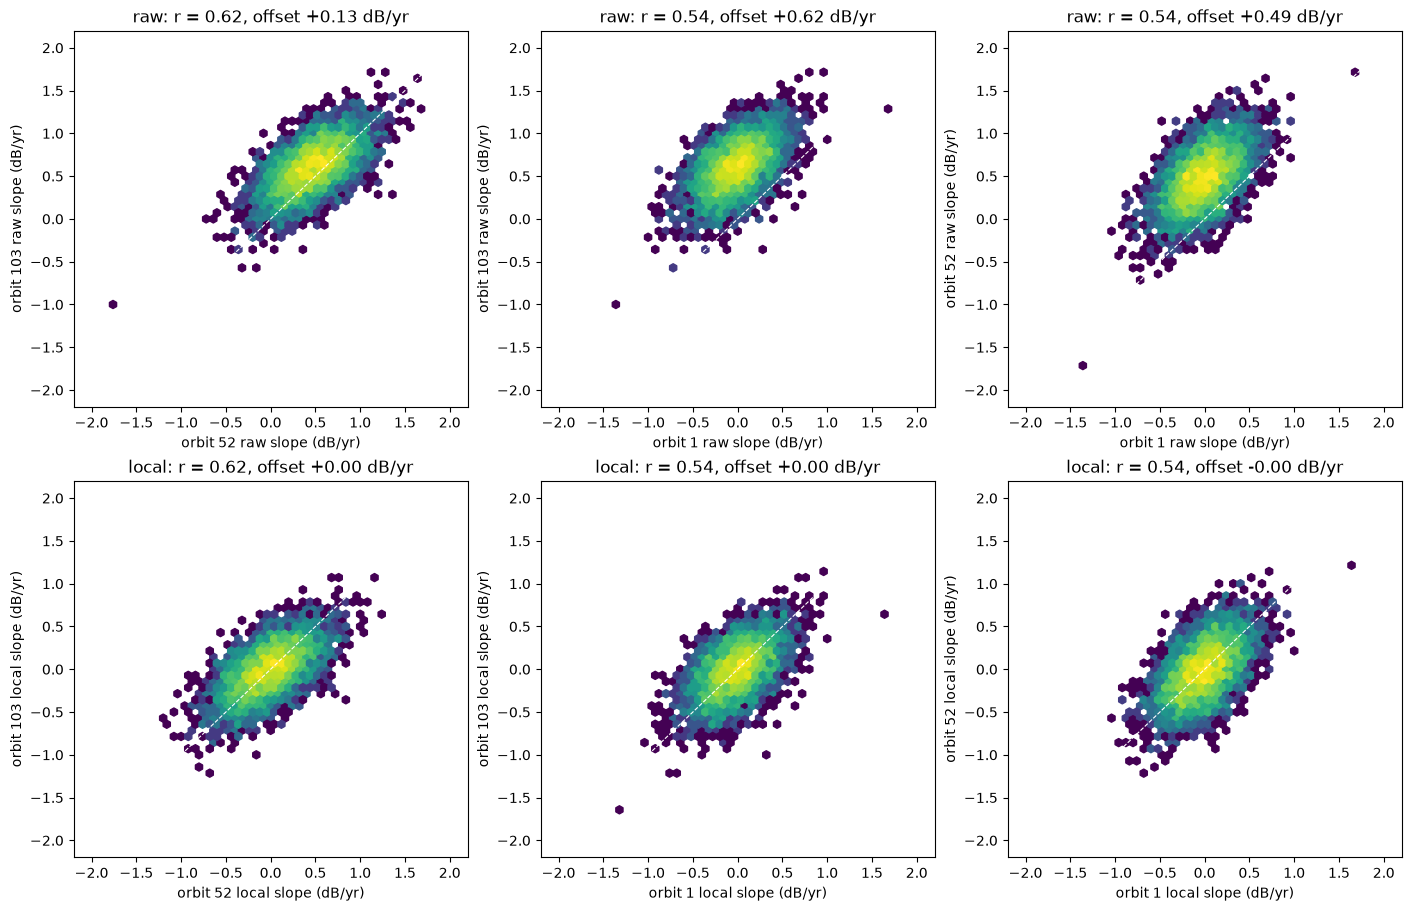

,slopes,pair,r,noise-corrected r,mean offset (dB/yr)
0,raw,52 vs 103,0.618,1.333,0.131
1,raw,1 vs 103,0.537,1.266,0.617
2,raw,1 vs 52,0.543,1.029,0.486
3,local,52 vs 103,0.618,1.333,0.004
4,local,1 vs 103,0.537,1.266,0.001
5,local,1 vs 52,0.543,1.029,-0.003


,moor-wide trend (dB/yr),local slope 5th pct,local slope 95th pct,median slope SE (dB/yr),reliability,median residual std (dB),cells with |t| > 2 (%)
orbit,,,,,,,
1,-0.00,-0.46,0.45,0.18,0.48,0.65,18.42
52,0.49,-0.53,0.53,0.18,0.58,0.64,24.05
103,0.62,-0.50,0.46,0.20,0.37,0.69,15.94


In [7]:
PAIRS = [(52, 103), (1, 103), (1, 52)]

# Reliability: the share of the across-cell variance in local slopes that isn't estimation
# noise, 1 - mean(SE^2) / var(slope). Dividing r by sqrt(rel_a * rel_b) gives the correlation
# the orbits would show without noise; values near (or above) 1 mean the disagreement
# between orbits is what noise alone would produce.
reliability = {}
for o in ORBITS:
    s, se = local_fits[o].slope[cell_ok], local_fits[o].se[cell_ok]
    reliability[o] = 1 - np.nanmean(se**2) / np.nanvar(s)

fig, axs = plt.subplots(2, 3, figsize=(14, 9), constrained_layout=True)
agreement = []
for i, (fits, kind) in enumerate([(raw_fits, "raw"), (local_fits, "local")]):
    for j, (a, b) in enumerate(PAIRS):
        sa, sb = fits[a].slope[cell_ok], fits[b].slope[cell_ok]
        ok = np.isfinite(sa) & np.isfinite(sb)
        r = np.corrcoef(sa[ok], sb[ok])[0, 1]
        offset = np.mean(sb[ok] - sa[ok])
        agreement.append({"slopes": kind, "pair": f"{a} vs {b}", "r": r,
                          "noise-corrected r": r / np.sqrt(reliability[a] * reliability[b]),
                          "mean offset (dB/yr)": offset})
        ax = axs[i, j]
        ax.hexbin(sa[ok], sb[ok], gridsize=50, extent=(-2, 2, -2, 2), bins="log", cmap="viridis")
        ax.plot([-2, 2], [-2, 2], "w--", lw=0.8)
        ax.set_xlabel(f"orbit {a} {kind} slope (dB/yr)")
        ax.set_ylabel(f"orbit {b} {kind} slope (dB/yr)")
        ax.set_title(f"{kind}: r = {r:.2f}, offset {offset:+.2f} dB/yr")
fig.savefig(OUT / "06_orbit_slope_agreement.png", dpi=120)
plt.show()
# r is the same for raw and local slopes: subtracting R(t) shifts every cell's slope by the same
# constant (the moor-wide trend), so only the offset between orbits changes.
display(pd.DataFrame(agreement).round(3))

# per-orbit summary of the local fits (t uses the autocorrelation-inflated SE)
display(pd.DataFrame({
    o: {"moor-wide trend (dB/yr)": moor_fits[o].slope,
        "local slope 5th pct": np.nanpercentile(f.slope[cell_ok], 5),
        "local slope 95th pct": np.nanpercentile(f.slope[cell_ok], 95),
        "median slope SE (dB/yr)": np.nanmedian(f.se[cell_ok]),
        "reliability": reliability[o],
        "median residual std (dB)": np.nanmedian(f.resid_std[cell_ok]),
        "cells with |t| > 2 (%)": 100 * np.nanmean(np.abs(f.t[cell_ok]) > 2)}
    for o, f in local_fits.items()}).T.round(2).rename_axis("orbit"))

### Choice of orbit

- **All three orbits see the same moor-wide signal.** Monthly means of $R(t)$ correlate at 0.71–0.87 between orbits, and the fitted annual cycle peaks in mid-February in all three (day 41–46).
- **They disagree on the moor-wide trend:** 0.00 (orbit 1), +0.49 (orbit 52) and +0.62 (orbit 103) dB/yr, each ± about 0.3. Orbit 1 also has the smallest annual amplitude (0.92 vs 1.45 dB for orbit 103) and is about 1.8 dB darker. Both fit its larger incidence angle (44.8°) making it less sensitive to surface wetness. The moor-wide trend is dominated by the 2023/2024 weather contrast anyway, so it isn't the quantity we map.
- **They agree on local slopes.** After subtracting $R(t)$ the offset between orbits is below 0.005 dB/yr. The cell-by-cell correlation is 0.54–0.62, but correcting for estimation noise in each cell gives values of 1 or more: the disagreement between orbits is what noise alone would produce. Combining orbits would reduce noise but wouldn't change the pattern.
- **So we use a single orbit: 103.** It has the smallest incidence angle (36.5°) and the largest seasonal amplitude, so it's the most sensitive to surface wetness. It's an evening pass, avoiding dawn dew and frost (orbit 52 passes at about 06:30). Each date is a single scene, without the seam in orbit 1.
- **Costs to note:** orbit 103 has the noisiest local slopes (reliability 0.37 vs 0.48–0.58; median slope SE 0.20 vs 0.18 dB/yr), and any moor-wide trend magnitude depends on which orbit is used.
- **Caveat:** noise-corrected correlations above 1 suggest the slope SEs are somewhat conservative, or that errors are shared between orbits (the same weather affects the same cells in every orbit). So agreement between orbits does not on its own show that the local slopes reflect lasting change rather than weather.

## AREA OF STUDY

The area east of Crowdy reservoir has restoration started during our time period (Jan 2023 to Dec 2024) so could be an interesting area to study. 

`make_study_areas.py` identifies parts of the crowdy restoration area which lie within the mask. We are calling this the "Treatment area". It then identifies a nearby patch of connected pixels with similar elevation and with a similar deep peat make-up which has the same area as the treatment area, to use as a control.

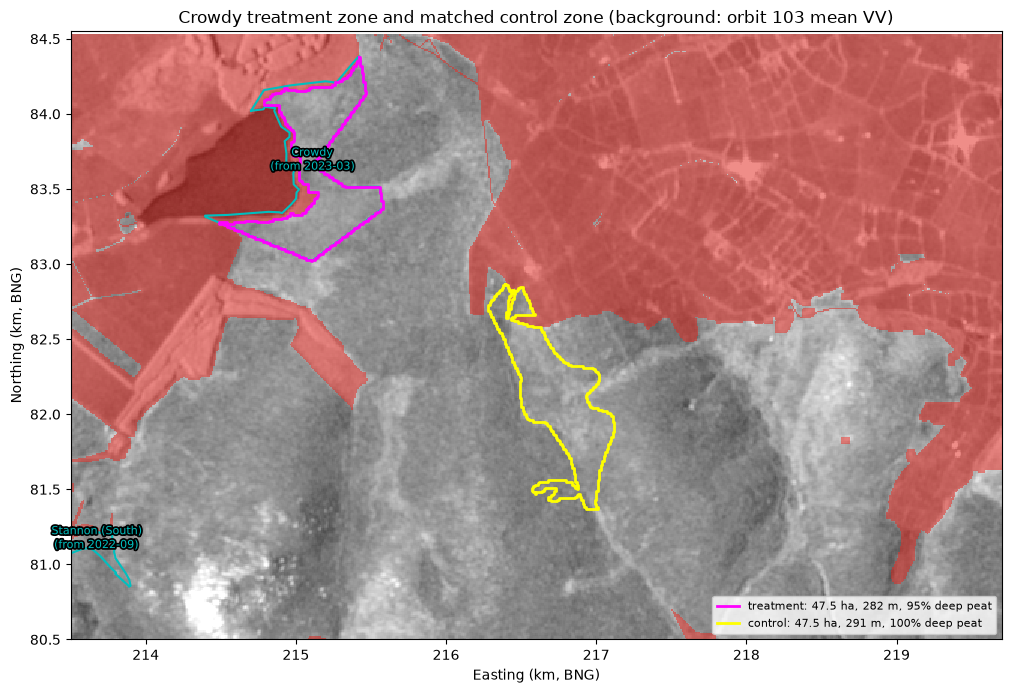

In [8]:
# Treatment = Crowdy restoration polygon ∩ peat mask; control = same number of unmasked
# deep-peat pixels east of Crowdy, matched on elevation (see make_study_areas.py)
study_areas = plot_helpers.get_study_areas()
ORBIT = 103  # single orbit from here on (see "Choice of orbit")
ZONE_COLORS = {"treatment": "magenta", "control": "yellow"}

fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)
plot_helpers.imshow_km(ax, np.nanmean(stacks[ORBIT], 0), cmap="gray", vmin=-22, vmax=-6)
plot_helpers.imshow_km(ax, np.where(keep, np.nan, 1), cmap="Reds", vmin=0, vmax=1.5, alpha=0.55)
plot_helpers.plot_restoration_areas(ax, restoration_areas, point_buffer_km=POINT_BUFFER_KM)
for name, zone in study_areas.items():
    for i, (x, y) in enumerate(zone["outlines"]):
        p = zone["properties"]
        ax.plot(x, y, "-", color=ZONE_COLORS[name], lw=2,
                label=(f"{name}: {p['area_ha']:.1f} ha, {p['mean_elev_m']:.0f} m, "
                       f"{p['deep_peat_frac']:.0%} deep peat") if i == 0 else None)
ax.set_xlim(213.5, 219.7)
ax.set_ylim(80.5, 84.55)
ax.legend(loc="lower right", fontsize=8)
ax.set_title(f"Crowdy treatment zone and matched control zone (background: orbit {ORBIT} mean VV)")
fig.savefig(OUT / "07_study_areas.png", dpi=110)
plt.show()

We see that that the selected control area is close to the masked-off area in the north-east and quite narrow. It also lies along a valley. We may choose a different control, or adjust this algorithm, later. 

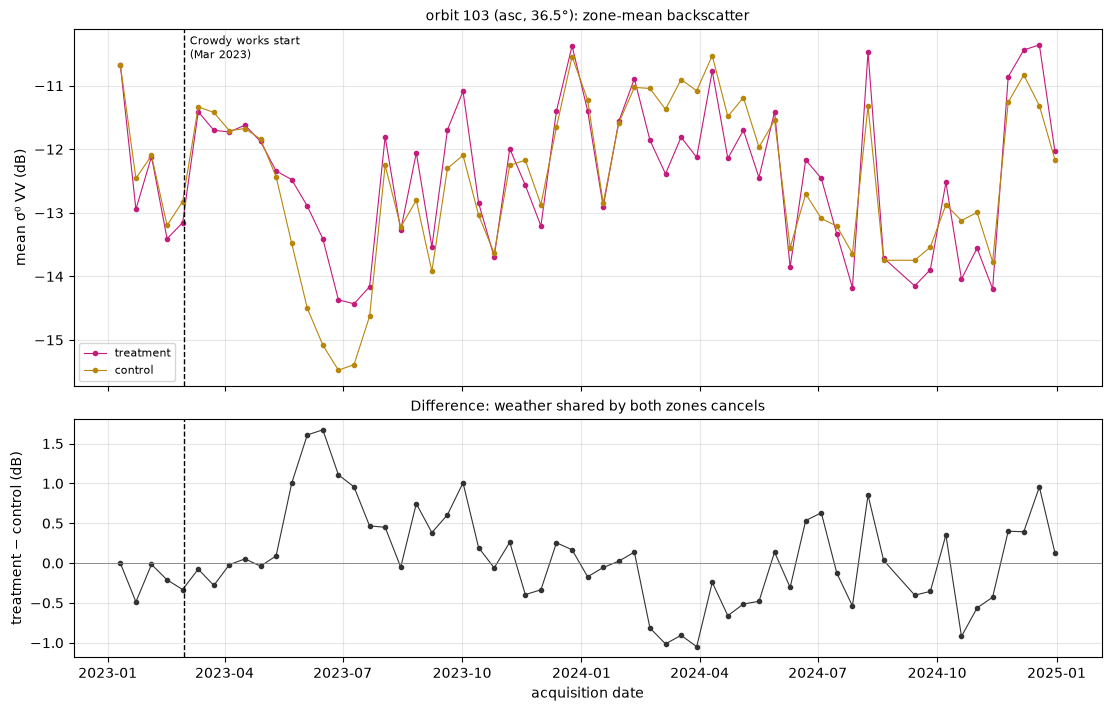

,n_before,diff_before_dB,n_after,diff_after_dB
orbit,,,,
103,5,-0.21,55,0.09


In [9]:
# zone-mean VV per acquisition: average of the zone's pixels in dB, one value per date
dates = idxs[ORBIT].time
series = {name: np.nanmean(stacks[ORBIT][:, zone["pixels"]], axis=1) for name, zone in study_areas.items()}
diff = series["treatment"] - series["control"]
works_start = pd.Timestamp(next(a for a in restoration_areas if a["name"] == "Crowdy")["start"])

TS_COLORS = {"treatment": "#c51b7d", "control": "#b8860b"}   # darker versions of the map colours

fig, axs = plt.subplots(2, 1, figsize=(11, 7), sharex=True, constrained_layout=True,
                        gridspec_kw={"height_ratios": [3, 2]})
ax = axs[0]
for name in study_areas:
    ax.plot(dates, series[name], "o-", ms=3, lw=0.8, color=TS_COLORS[name], label=name)
ax.set_ylabel("mean σ⁰ VV (dB)")
ax.set_title(f"{ORBITS[ORBIT]}: zone-mean backscatter", fontsize=10)
ax.legend(fontsize=8, loc="lower left")

ax = axs[1]
ax.plot(dates, diff, "o-", ms=3, lw=0.8, color="0.2")
ax.axhline(0, color="0.5", lw=0.6)
ax.set_ylabel("treatment − control (dB)")
ax.set_title("Difference: weather shared by both zones cancels", fontsize=10)
ax.set_xlabel("acquisition date")

for ax in axs:
    ax.axvline(works_start, color="k", ls="--", lw=1)
    ax.grid(alpha=0.3)
axs[0].annotate(f"Crowdy works start\n({works_start:%b %Y})", (works_start, 1), xycoords=("data", "axes fraction"),
                xytext=(4, -4), textcoords="offset points", va="top", fontsize=8)
fig.savefig(OUT / "08_study_area_timeseries.png", dpi=120)
plt.show()

# mean difference before vs after the works start date (few dates before!)
before = (dates < works_start).to_numpy()
pd.DataFrame([{"n_before": before.sum(), "diff_before_dB": diff[before].mean(),
               "n_after": (~before).sum(), "diff_after_dB": diff[~before].mean()}],
             index=pd.Index([ORBIT], name="orbit")).round(2)


## FIGURES FOR THE WRITE-UP

The two figures for the two-page write-up (`write_up/main.tex`), both from orbit 103:

1. **Time series:** the Crowdy restoration patch and its matched control, with the fitted trend + annual cycle for each, and their difference.
2. **Trend map:** the local slope (relative to the moor-wide signal) in every 100 m cell, with the cells that show the same significant trend in all three orbits marked.

They are sized for one column of the two-column write-up and saved as PDF to `write_up/figures/` (the file names `main.tex` expects), and as PNG to `eda_figures/`.

In [19]:
import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.patheffects as pe

FIG_DIR = Path("../write_up/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
COL_W = 3.35  # inches: one column of the two-column write-up
PAPER_RC = {"font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 6.5,
            "ytick.labelsize": 6.5, "legend.fontsize": 6, "axes.linewidth": 0.6,
            "figure.dpi": 220,    # inline display: a column-width figure is ~740 px wide
            "savefig.dpi": 400}   # PNG copies; the PDFs are vector
# Met Office: June 2023 was the UK's warmest June on record, with 68% of average rainfall
DROUGHT = (pd.Timestamp("2023-06-01"), pd.Timestamp("2023-07-01"))
ZONE_LABELS = {"treatment": "Crowdy restoration", "control": "matched control"}

### Figure 1: Crowdy restoration patch and matched control

The same zone-mean series as above, now with the trend + annual cycle model (`trend.fit_series`) fitted to each zone and to their difference. The legend gives each fitted trend ± its autocorrelation-inflated standard error.

Each zone's own trend includes the moor-wide weather signal, so the difference (lower panel) is the quantity of interest: weather shared by both zones cancels. The shaded band is June 2023, the record-warm, dry month.

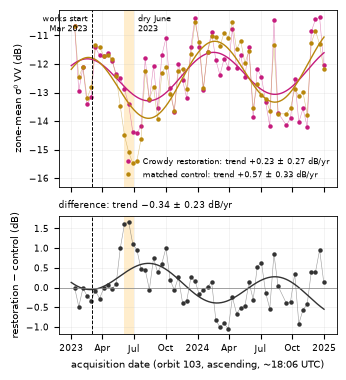

,trend (dB/yr),trend SE,annual amplitude (dB),residual std (dB)
Crowdy restoration,0.23,0.27,0.79,1.03
matched control,0.57,0.33,1.20,0.92
restoration − control,-0.34,0.23,0.41,0.53


In [20]:
zone_fits = {name: fit_series(tyears[ORBIT], s) for name, s in series.items()}
diff_fit = fit_series(tyears[ORBIT], diff)


def trend_label(f) -> str:
    """'+0.23 ± 0.27 dB/yr', with a proper minus sign."""
    return f"{f.slope:+.2f} ± {f.se:.2f} dB/yr".replace("-", "−")


def legend_key(color, label):
    """Marker-only legend entry (the framed legend box keeps it from looking like data)."""
    return mpl.lines.Line2D([], [], color=color, marker="o", ms=2.2, ls="none", label=label)


LEGEND_KW = dict(loc="lower right", frameon=True, framealpha=0.95, edgecolor="0.7", fancybox=False)


with mpl.rc_context(PAPER_RC):
    fig, axs = plt.subplots(2, 1, figsize=(COL_W, COL_W * 1.1), sharex=True, constrained_layout=True,
                            gridspec_kw={"height_ratios": [3, 2]})
    ax = axs[0]
    for name in ("treatment", "control"):
        f, c = zone_fits[name], TS_COLORS[name]
        ax.plot(dates, series[name], "-", lw=0.4, alpha=0.5, color=c)
        ax.plot(dates, series[name], "o", ms=2.2, color=c)
        ax.plot(tt_dates, design(tt) @ f.beta, "-", lw=1, color=c)
    ax.set_ylabel("zone-mean σ⁰ VV (dB)")
    ax.set_ylim(bottom=-17.0)  # room for the legend below the data
    ax.legend(handles=[legend_key(TS_COLORS[n], f"{ZONE_LABELS[n]}: trend {trend_label(zone_fits[n])}")
                       for n in ("treatment", "control")], **LEGEND_KW)

    ax = axs[1]
    ax.plot(dates, diff, "-", lw=0.4, alpha=0.5, color="0.2")
    ax.plot(dates, diff, "o", ms=2.2, color="0.2")
    ax.plot(tt_dates, design(tt) @ diff_fit.beta, "-", lw=1, color="0.2")
    ax.axhline(0, color="0.5", lw=0.5)
    ax.set_ylabel("restoration − control (dB)")
    ax.set_ylim(bottom=-1.75)  # room for the legend below the data
    ax.legend(handles=[legend_key("0.2", f"restoration − control: trend {trend_label(diff_fit)}")], **LEGEND_KW)
    ax.set_xlabel("acquisition date (orbit 103, ascending, ~18:06 UTC)")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))

    for ax in axs:
        ax.axvspan(*DROUGHT, color="orange", alpha=0.2, lw=0)
        ax.axvline(works_start, color="k", ls="--", lw=0.7)
        ax.grid(alpha=0.25, lw=0.4)
    # in the gap between the panels, centred on the dashed line so it can't be read as labelling the band
    axs[1].annotate(f"works start\n{works_start:%b %Y}", (works_start, 1), xycoords=("data", "axes fraction"),
                    xytext=(0, 2), textcoords="offset points", ha="center", va="bottom", fontsize=6)
    axs[0].annotate("dry June\n2023", (DROUGHT[1], 0.98), xycoords=("data", "axes fraction"),
                    xytext=(3, 0), textcoords="offset points", ha="left", va="top", fontsize=6)
    fig.savefig(FIG_DIR / "timeseries.pdf")
    fig.savefig(OUT / "09_writeup_timeseries.png")
    plt.show()

display(pd.DataFrame({ZONE_LABELS.get(k, k): {"trend (dB/yr)": f.slope, "trend SE": f.se,
                                               "annual amplitude (dB)": f.amplitude, "residual std (dB)": f.resid_std}
                      for k, f in {**zone_fits, "restoration − control": diff_fit}.items()}).T.round(2))

### Figure 2: local trend map

The map shows the orbit-103 local slope: each 100 m cell's trend after subtracting the moor-wide signal $R(t)$ (section "Subtracting the moor-wide signal"). The raw slope is the local slope plus the moor-wide trend (+0.62 dB/yr for orbit 103) in every cell, so the raw map is the same pattern shifted towards red; that shift is mostly the 2023/2024 weather contrast.

Most local slopes are within noise (reliability 0.37 for orbit 103). To mark where the change is clearest, we use the three orbits as independent looks at the same ground: a cell is **robust** if its local slope is significant ($|t| > 2$, with the autocorrelation-inflated SE) and has the same sign in all three orbits. We compare the number of robust cells with the number expected if the three orbits were independent. They aren't fully independent (they share the weather), so this is a screening criterion, not a formal test.

robust cells: 129 of 3801 (3.4%): 70 brightening, 59 darkening; 7 expected if the orbits were independent
moor-wide trend (orbit 103): +0.62 ± 0.33 dB/yr


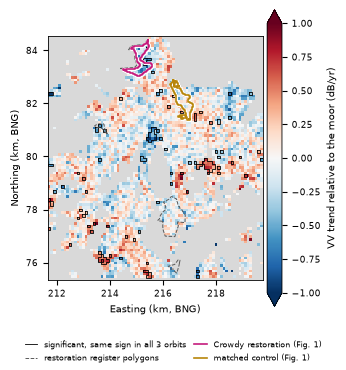

In [21]:
from affine import Affine
from rasterio.features import shapes

# +1 / -1 where a cell's local slope is significant (|t| > 2) and positive / negative, else 0
sig = np.stack([np.nan_to_num(np.sign(local_fits[o].slope) * (np.abs(local_fits[o].t) > 2)) for o in ORBITS])
robust = cell_ok & (sig != 0).all(0) & (sig == sig[0]).all(0)
p_pos = [np.mean(s[cell_ok] == 1) for s in sig]
p_neg = [np.mean(s[cell_ok] == -1) for s in sig]
expected = (np.prod(p_pos) + np.prod(p_neg)) * cell_ok.sum()
n_up, n_down = int((robust & (sig[0] > 0)).sum()), int((robust & (sig[0] < 0)).sum())
print(f"robust cells: {robust.sum()} of {cell_ok.sum()} ({robust.sum() / cell_ok.sum():.1%}): "
      f"{n_up} brightening, {n_down} darkening; {expected:.0f} expected if the orbits were independent")
print(f"moor-wide trend (orbit {ORBIT}): {moor_fits[ORBIT].slope:+.2f} ± {moor_fits[ORBIT].se:.2f} dB/yr")

# outlines of robust cells (pixel edges, km), from the 100 m grid's own transform
cell_km = (EXT_100M[1] - EXT_100M[0]) / robust.shape[1]  # 0.1 km
T100 = Affine(cell_km, 0, EXT_100M[0], 0, -cell_km, EXT_100M[3])
robust_rings = [np.array(ring).T for geom, _ in shapes(robust.astype("uint8"), mask=robust, transform=T100)
                for ring in geom["coordinates"]]
halo = [pe.withStroke(linewidth=2.2, foreground="white")]

with mpl.rc_context(PAPER_RC):
    fig, ax = plt.subplots(figsize=(COL_W, 3.55), constrained_layout=True)
    ax.set_facecolor("0.85")
    im = plot_helpers.imshow_km(ax, local_fits[ORBIT].slope, EXT_100M, cmap="RdBu_r", vmin=-1, vmax=1)
    for i, (x, y) in enumerate(robust_rings):
        ax.plot(x, y, "-", color="k", lw=0.6, label="significant, same sign in all 3 orbits" if i == 0 else None)
    for i, a in enumerate(a for a in restoration_areas if a["kind"] == "polygon"):
        for j, (x, y) in enumerate(a["outlines"]):
            ax.plot(x, y, "--", color="0.35", lw=0.7,
                    label="restoration register polygons" if i == j == 0 else None)
    for name, zone in study_areas.items():
        for i, (x, y) in enumerate(zone["outlines"]):
            ax.plot(x, y, "-", color=TS_COLORS[name], lw=1.2, path_effects=halo,
                    label=f"{ZONE_LABELS[name]} (Fig. 1)" if i == 0 else None)
    ax.set_xlim(plot_helpers.KM[:2])
    ax.set_ylim(plot_helpers.KM[2:])
    ax.set_xticks(np.arange(212, 220, 2))
    # colorbar in an inset so it matches the map's height (ax=ax would size it to the layout slot)
    cax = ax.inset_axes([1.03, 0, 0.035, 1])
    fig.colorbar(im, cax=cax, extend="both", label="VV trend relative to the moor (dB/yr)")
    fig.legend(loc="outside lower center", ncol=2, frameon=False,
               handlelength=1.5, columnspacing=1.0, )
    fig.savefig(FIG_DIR / "trend_map.pdf")
    fig.savefig(OUT / "10_writeup_trend_map.png")
    plt.show()